# МобиКар: анализ продуктовой воронки

Кейс отбора на стажировку в Т-Банк. Анализ переходов от установки приложения до первой поездки.

**Данные:** 56 дней, 8 недель, 6 этапов воронки. Таблица восстановлена из предоставленного блока чисел. Все 48 средних дневных конверсий совпадают с сохранённым выводом исходного notebook до 6 знаков после запятой. Это проверка воспроизводимости результатов, а не подтверждение побайтовой идентичности исходного Excel.

## 1. Загрузка и проверка данных
CSV и Excel содержат одинаковые значения. Основной анализ читает CSV и запускается из корня репозитория или папки `notebooks`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data/funnel-daily.csv").exists():
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data/funnel-daily.csv", parse_dates=["Дата"])
stages = ["Установки", "Регистрации", "Открыли поиск", "Просмотрели авто", "Забронировали", "Первая поездка"]
assert df.shape == (56, 8)
assert not df.isna().any().any()
assert df["Дата"].is_unique
assert (df[stages] > 0).all().all()
for previous, current in zip(stages, stages[1:]):
    assert (df[current] <= df[previous]).all()
assert df.groupby("Неделя").size().eq(7).all()
print(f"Данные: {len(df)} дней, {df['Неделя'].nunique()} недель.")
print(df.head().to_string(index=False))


Данные: 56 дней, 8 недель.
      Дата   Неделя  Установки  Регистрации  Открыли поиск  Просмотрели авто  Забронировали  Первая поездка
2025-01-06 Неделя 1        206          130             91                70             57              51
2025-01-07 Неделя 1        216          138             98                73             55              48
2025-01-08 Неделя 1        181          117             86                69             52              46
2025-01-09 Неделя 1        212          134            101                83             64              54
2025-01-10 Неделя 1        218          143             97                73             60              53


## 2. Исходный расчёт и график

Дневная конверсия — отношение числа пользователей следующего этапа к предыдущему. В исходном решении использовалось среднее дневных конверсий за неделю. Ниже сохранён тот же расчёт и логика графика. Изменены только загрузка данных и сохранение графика в репозиторий.


     Неделя  conv_reg  conv_search  conv_view  conv_book  conv_ride  conv_total
0  Неделя 1  0.653405     0.723127   0.792709   0.785872   0.871173    0.256560
1  Неделя 2  0.658673     0.707754   0.788426   0.784390   0.895579    0.258875
2  Неделя 3  0.678864     0.741822   0.805241   0.757274   0.861082    0.264176
3  Неделя 4  0.679917     0.720823   0.798118   0.755989   0.877715    0.259325
4  Неделя 5  0.667020     0.727620   0.798023   0.789719   0.873509    0.267299
5  Неделя 6  0.679359     0.709472   0.789774   0.797008   0.907446    0.274835
6  Неделя 7  0.669353     0.493459   0.840591   0.793232   0.842622    0.185446
7  Неделя 8  0.675320     0.503321   0.812615   0.795555   0.893826    0.196772


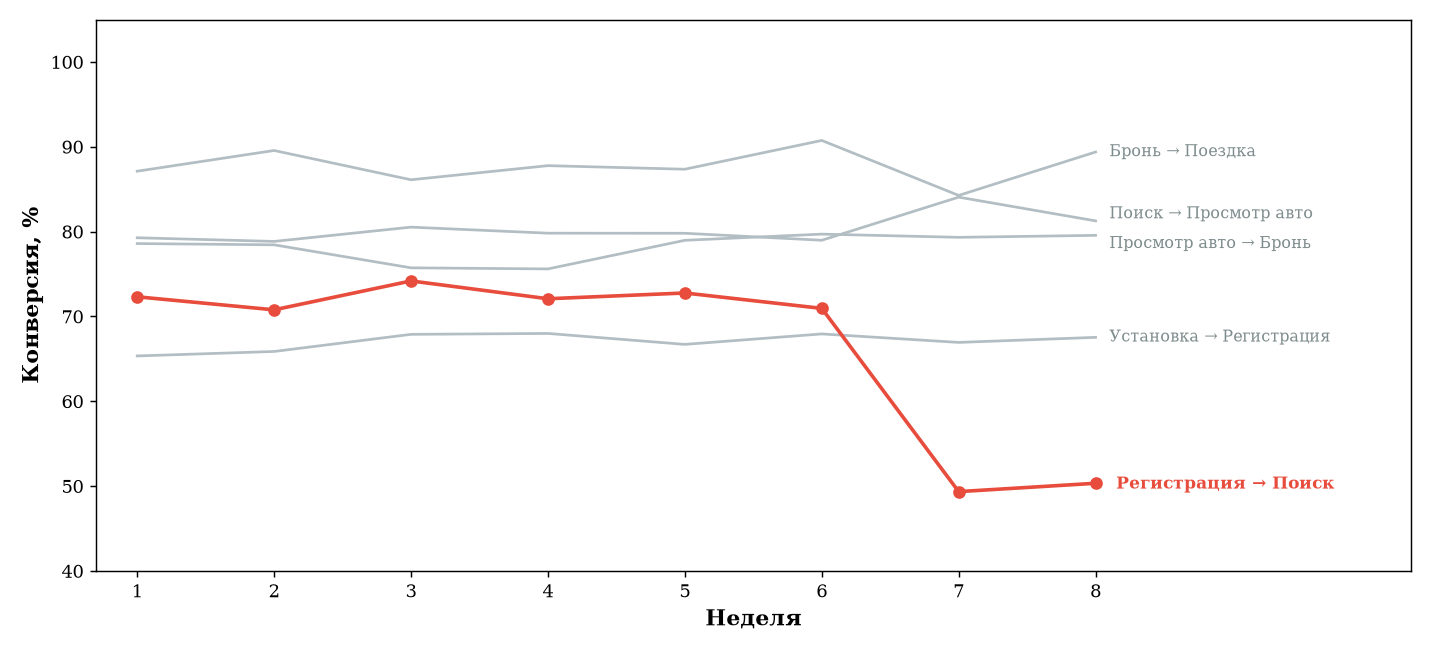

In [2]:
plt.rc('font', family='serif')
plt.rc('axes', titlesize=18, titleweight='bold')


df['conv_reg'] = df['Регистрации'] / df['Установки']
df['conv_search'] = df['Открыли поиск'] / df['Регистрации']
df['conv_view'] = df['Просмотрели авто'] / df['Открыли поиск']
df['conv_book'] = df['Забронировали'] / df['Просмотрели авто']
df['conv_ride'] = df['Первая поездка'] / df['Забронировали']
df['conv_total'] = df['Первая поездка'] / df['Установки']

weekly = df.groupby('Неделя').agg({
    'conv_reg': 'mean',
    'conv_search': 'mean',
    'conv_view': 'mean',
    'conv_book': 'mean',
    'conv_ride': 'mean',
    'conv_total': 'mean'
}).reset_index()

print(weekly)

weeks = list(range(1,9))

search_conv = weekly['conv_search'] * 100
reg_conv = weekly['conv_reg'] * 100
view_conv = weekly['conv_view'] * 100
book_conv = weekly['conv_book'] * 100
ride_conv = weekly['conv_ride'] * 100

plt.figure(figsize=(11, 5))
plt.xticks(weeks)

plt.plot(weeks, reg_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, view_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, book_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, ride_conv, marker='', linewidth=1.5, color='#b2bec3')
plt.plot(weeks, search_conv, marker='o', linewidth=2, color='#e74c3c')

plt.ylabel('Конверсия, %', fontsize=12, fontweight='bold')
plt.xlabel('Неделя', fontsize=12, fontweight='bold')
plt.ylim(40, 105)
plt.xlim(0.7, 10.3)

plt.text(8.1, reg_conv.iloc[-1], 'Установка → Регистрация', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.1, view_conv.iloc[-1]+0.8, 'Поиск → Просмотр авто', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.1, book_conv.iloc[-1]-1, 'Просмотр авто → Бронь', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.1, ride_conv.iloc[-1], 'Бронь → Поездка', fontsize=9, color='#7f8c8d', va='center')
plt.text(8.15, search_conv.iloc[-1]-0.1, 'Регистрация → Поиск', fontsize=9.5, color='#e74c3c', va='center', fontweight='bold')


plt.tight_layout()
plt.savefig(ROOT / "assets/funnel.ru.png", dpi=160)
plt.show()



## 3. Основной вывод

На этапе **«Регистрация → Поиск»** средняя дневная конверсия снизилась с **70,95% до 49,35%** между неделями 6 и 7: **−21,60 п. п.** Общая конверсия «Установка → Первая поездка» за тот же интервал снизилась с **27,48% до 18,54%**.

Согласно условию задания, менялся поиск авто, а установки выросли, удержание D7 и отзывы не ухудшились. Это вводные кейса; таблица не содержит удержания или отзывов. Динамика воронки помогает локализовать проблему, но сама по себе не устанавливает её причину.

## 4. Дополнительная проверка метода агрегирования

Среднее дневных отношений и отношение недельных сумм — разные метрики. Первая одинаково взвешивает дни; вторая взвешивает их числом пользователей предыдущего этапа. Для общего недельного показателя рассчитываем второй вариант и сравниваем вывод.


In [3]:
stage_metrics = ["conv_reg", "conv_search", "conv_view", "conv_book", "conv_ride"]
weekly_counts = df.groupby("Неделя")[stages].sum()
weekly_weighted = pd.DataFrame(index=weekly_counts.index)
for metric, previous, current in zip(stage_metrics, stages, stages[1:]):
    weekly_weighted[metric] = weekly_counts[current] / weekly_counts[previous]
weekly_weighted["conv_total"] = weekly_counts["Первая поездка"] / weekly_counts["Установки"]

comparison = pd.DataFrame({
    "Среднее дневных, %": weekly.set_index("Неделя")["conv_search"] * 100,
    "Отношение сумм, %": weekly_weighted["conv_search"] * 100,
})
print(comparison.round(2).to_string())
change = (weekly_weighted.loc["Неделя 7", "conv_search"] - weekly_weighted.loc["Неделя 6", "conv_search"]) * 100
print(f"Переход к поиску, недели 6 → 7, отношение сумм: {change:.2f} п. п.")


          Среднее дневных, %  Отношение сумм, %
Неделя                                         
Неделя 1               72.31              72.30
Неделя 2               70.78              70.85
Неделя 3               74.18              74.10
Неделя 4               72.08              71.97
Неделя 5               72.76              72.80
Неделя 6               70.95              70.82
Неделя 7               49.35              49.36
Неделя 8               50.33              50.34
Переход к поиску, недели 6 → 7, отношение сумм: -21.46 п. п.


## 5. Гипотезы и план проверки

| Гипотеза | Проверка |
| --- | --- |
| Интерфейс поиска стал менее понятным | Изучить события после регистрации, путь до открытия поиска и обратную связь |
| В поиске появились технические проблемы | Проверить ошибки, логи и доступность поиска |
| Появились дополнительные барьеры | Сравнить сценарии, города, устройства и версии приложения |

Для проверки влияния изменений поиска предложен A/B-тест с контрольной версией. Эксперимент не проводился в рамках представленного анализа.
